# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

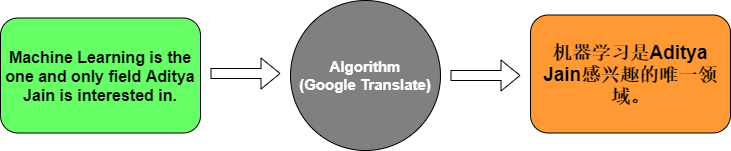

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1429 - loss: 2.4844

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.1429 - loss: 2.4844 - val_accuracy: 0.0000e+00 - val_loss: 2.4877


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7143 - loss: 2.4758

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7143 - loss: 2.4758 - val_accuracy: 0.0000e+00 - val_loss: 2.4904


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 1.0000 - loss: 0.5530 - val_accuracy: 0.0000e+00 - val_loss: 5.4060


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.5714 - loss: 1.8675

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.5714 - loss: 1.8675


Test Accuracy: 0.5714285969734192


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

**1. Embedding layer:** It turns each word index (an integer such as 2 for "how") into a dense vector of 64 numbers (output_dim=64). The integer is just a row number in a table of learned vectors. During training these vectors are adjusted, so words used in similar ways end up with similar vectors.

**3. Encoder LSTM:** It reads the English sentence one word vector at a time and keeps a memory (hidden state) of what it has read so far. Because return_sequences is not set, it returns only its final hidden state: one 64-number vector that summarizes the whole English sentence. RepeatVector then copies this summary once for each position in the French sentence.

**5. Decoder LSTM:** It takes the repeated sentence summary and produces the output sentence one step at a time. With return_sequences=True it returns a hidden state for **every** time step (one per French word position), and each of these is turned into a French word by the final layer.

**8. Why softmax:** At each time step the Dense layer gives one score for every word in the French vocabulary. Softmax turns these scores into probabilities between 0 and 1 that add up to 1. We can then pick the most likely word with argmax, and the sparse_categorical_crossentropy loss can compare the predicted probabilities with the correct French word index.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

#### Step 1: Load the dataset

The dataset has about 175,000 English-French sentence pairs. It is downloaded with kagglehub (Lab 1) and loaded with pandas.

In [8]:
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
df = pd.read_csv(path + "/eng_-french.csv")
print("Number of sentence pairs:", len(df))
df.head()

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


To keep training fast on a CPU, we keep only short sentences (up to 4 English words and 5 French words) and use train_test_split to take a random sample of 15,000 pairs.

In [9]:
english_all = df["English words/sentences"]
french_all = df["French words/sentences"]

short_english = [e for e, f in zip(english_all, french_all) if len(e.split()) <= 4 and len(f.split()) <= 5]
short_french = [f for e, f in zip(english_all, french_all) if len(e.split()) <= 4 and len(f.split()) <= 5]
print("Short pairs:", len(short_english))

english, _, french, _ = train_test_split(short_english, short_french, train_size=15000, random_state=42)
print("Pairs used:", len(english))
print(english[:5])
print(french[:5])

Short pairs: 37309
Pairs used: 15000
['Terrific!', 'Put away your wallet.', "I'll foot the bill.", "I've failed.", 'Father manages the store.']
['Excellent\u202f!', 'Range ton portefeuille.', "Je paierai l'addition.", "J'ai échoué.", 'Papa gère le magasin.']


#### Step 2: Tokenize and pad

Same steps as above: one Tokenizer per language, then pad_sequences so all sentences have the same length. The Tokenizer also lowercases the text and removes punctuation.

In [10]:
tokenizer_eng2 = Tokenizer()
tokenizer_eng2.fit_on_texts(english)
eng_padded2 = pad_sequences(tokenizer_eng2.texts_to_sequences(english))

tokenizer_frn2 = Tokenizer()
tokenizer_frn2.fit_on_texts(french)
frn_padded2 = pad_sequences(tokenizer_frn2.texts_to_sequences(french))

print("English vocabulary size:", len(tokenizer_eng2.word_index))
print("French vocabulary size:", len(tokenizer_frn2.word_index))
print("English padded shape:", eng_padded2.shape)
print("French padded shape:", frn_padded2.shape)

English vocabulary size: 4454
French vocabulary size: 7562
English padded shape: (15000, 7)
French padded shape: (15000, 7)


#### Step 3: Build and train the model

Same encoder-decoder LSTM as above (Embedding → LSTM → RepeatVector → LSTM → TimeDistributed Dense). Because the vocabulary is much larger, we use bigger layers (128-dimensional embeddings, 256 LSTM units) and a batch size of 64.

In [11]:
eng_train2, eng_test2, frn_train2, frn_test2 = train_test_split(eng_padded2, frn_padded2, test_size=0.2, random_state=42)

model2 = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(tokenizer_eng2.word_index) + 1, output_dim=128),
    tf.keras.layers.LSTM(256),
    tf.keras.layers.RepeatVector(frn_padded2.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(tokenizer_frn2.word_index) + 1, activation='softmax'))
])

model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model2.fit(eng_train2, np.expand_dims(frn_train2, -1), epochs=30, batch_size=64, validation_split=0.1)

loss, accuracy = model2.evaluate(eng_test2, np.expand_dims(frn_test2, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/30


  1/169 ━━━━━━━━━━━━━━━━━━━━ 3:21 1s/step - accuracy: 0.0000e+00 - loss: 8.9309

  4/169 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.3387 - loss: 8.9227    

  7/169 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.3935 - loss: 8.8882

 10/169 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.4165 - loss: 8.7224

 12/169 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.4228 - loss: 8.4761

... (1,794 outputs left out)

81/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4842 - loss: 3.7224

91/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4835 - loss: 3.7273

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4837 - loss: 3.7256


Test Accuracy: 0.48371434211730957

#### Step 4: Translate

We translate some test sentences (the model never saw them during training) and compare them with the correct French translation.

In [12]:
test_english = tokenizer_eng2.sequences_to_texts(eng_test2[:15])
test_french = tokenizer_frn2.sequences_to_texts(frn_test2[:15])
test_predicted = tokenizer_frn2.sequences_to_texts(np.argmax(model2.predict(eng_test2[:15]), axis=-1))

for eng, frn, pred in zip(test_english, test_french, test_predicted):
    print(f"English:   {eng}")
    print(f"Correct:   {frn}")
    print(f"Predicted: {pred}")
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


English:   i hope it's over
Correct:   j'espère que c'est terminé
Predicted: je suis pas ici

English:   i felt ill
Correct:   je me sentais malade
Predicted: je ne pas pas pas

English:   did you enjoy yourself
Correct:   vous êtes vous amusé
Predicted: vous vous vous

English:   i opened the window
Correct:   j'ai ouvert la fenêtre
Predicted: il est est le

English:   what's going on
Correct:   qu'est ce qui se passe 
Predicted: il est le

English:   this is bad
Correct:   ce n'est pas bon
Predicted: c'est c'est

English:   don't be naive
Correct:   ne soyez pas naïf
Predicted: ne pas pas pas

English:   what have you done
Correct:   qu'avez vous fait
Predicted: je vous vous

English:   i am cooking now
Correct:   je cuisine en ce moment
Predicted: j'ai le très ici

English:   play that song again
Correct:   rejouez cette chanson
Predicted: il est est la

English:   tom isn't your brother
Correct:   tom n'est pas votre frère
Predicted: a pas de la

English:   tom was extremely impoli

In [13]:
def translate_sentence2(sentence):
    sequence = tokenizer_eng2.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded2.shape[1])
    predicted_sequence = model2.predict(padded_sequence)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    return tokenizer_frn2.sequences_to_texts(translated_sequence)[0]

for sentence in ["I like it.", "It is very good.", "This is expensive.", "Thank you.", "I want to buy this."]:
    print(f"{sentence} -> {translate_sentence2(sentence)}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step


I like it. -> le
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


It is very good. -> c'est est est
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


This is expensive. -> c'est c'est
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


Thank you. -> vous vous
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


I want to buy this. -> vous le ici


**Results:**

The model reaches about **48% test accuracy**. It learned some common French sentence starts such as "je", "vous", "c'est" and "ne ... pas", but most translations are wrong and repeat words ("je ne pas pas pas", "c'est c'est"). This happens because the encoder squeezes the whole English sentence into one vector, and 15,000 short pairs with 30 epochs on a CPU are not enough to learn a vocabulary of about 7,500 French words.

**For the e-commerce company:** this simple model shows how machine translation works, but its output is not good enough for product listings or customer reviews. Better results would need much more training data, longer training, and a stronger model, such as the pre-trained translation model used in Lab 7.